C:\Users\User\AppData\Local\Temp\ipykernel_15800\3694821123.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x='Gls', y='Player', data=top_scorers, palette='Blues_r')


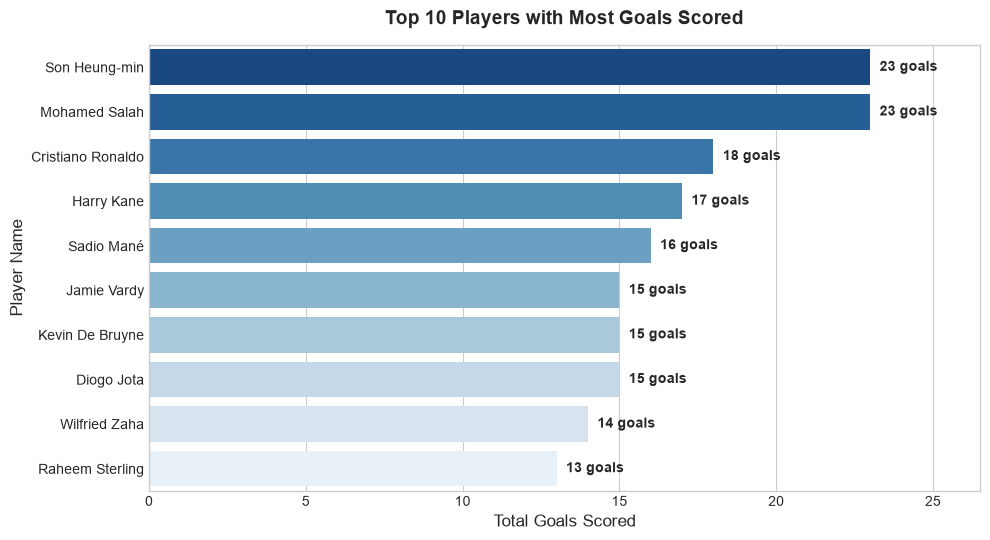

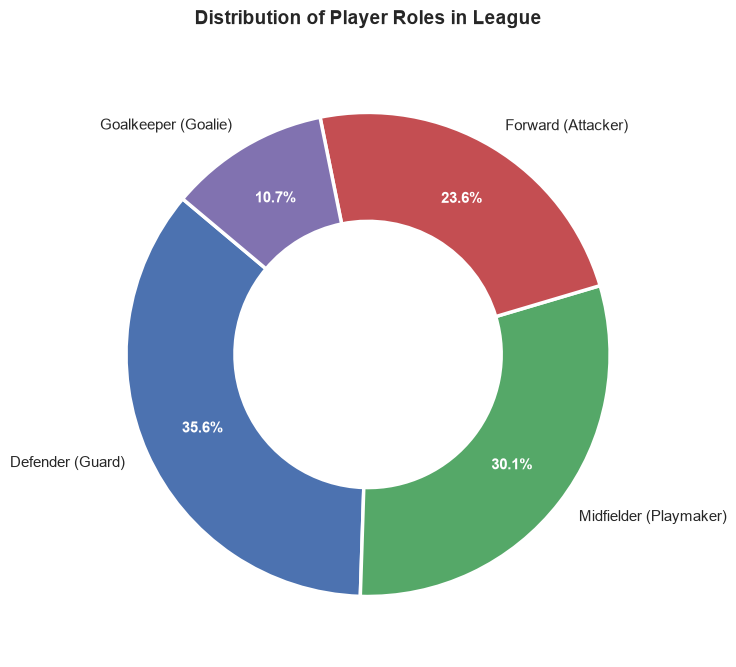

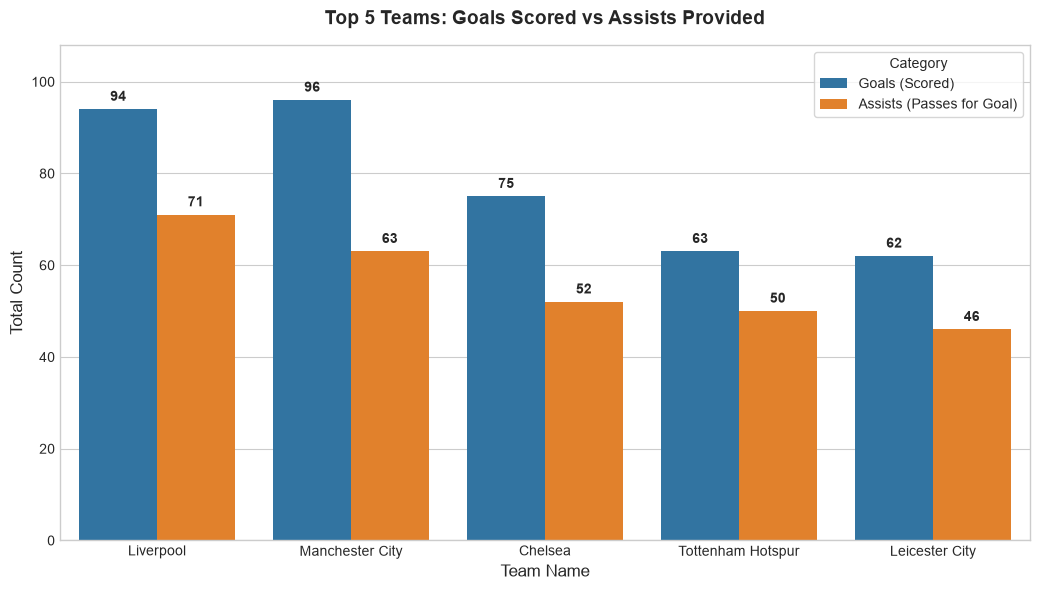

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\User\Desktop\football.csv")

plt.style.use('seaborn-v0_8-whitegrid')

plt.figure(figsize=(10, 5.5))
top_scorers = df.groupby('Player')['Gls'].sum().reset_index().sort_values(by='Gls', ascending=False).head(10)

ax1 = sns.barplot(x='Gls', y='Player', data=top_scorers, palette='Blues_r')
plt.title('Top 10 Players with Most Goals Scored', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Total Goals Scored', fontsize=12)
plt.ylabel('Player Name', fontsize=12)

for p in ax1.patches:
    width = p.get_width()
    ax1.annotate(f'{int(width)} goals',
                 (width + 0.3, p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', fontsize=10, fontweight='bold')

plt.xlim(0, max(top_scorers['Gls']) + 3.5)
plt.tight_layout()
plt.savefig('top_scorers.png', dpi=300)
plt.show()

df['Primary_Pos'] = df['Pos'].astype(str).apply(lambda x: x.split(',')[0] if pd.notnull(x) else 'Unknown')
pos_map = {
    'FW': 'Forward (Attacker)',
    'MF': 'Midfielder (Playmaker)',
    'DF': 'Defender (Guard)',
    'GK': 'Goalkeeper (Goalie)'
}
df['Pos_Name'] = df['Primary_Pos'].map(pos_map).fillna(df['Primary_Pos'])

plt.figure(figsize=(7.5, 7.5))
pos_counts = df['Pos_Name'].value_counts()

colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B0']
wedges, texts, autotexts = plt.pie(
    pos_counts, 
    labels=pos_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2.5),
    textprops={'fontsize': 11}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_weight('bold')

plt.title('Distribution of Player Roles in League', fontsize=14, pad=20, fontweight='bold')
plt.tight_layout()
plt.savefig('positions_donut.png', dpi=300)
plt.show()

plt.figure(figsize=(10.5, 6))
team_stats = df.groupby('Team')[['Gls', 'Ast']].sum().reset_index()
team_stats['Total'] = team_stats['Gls'] + team_stats['Ast']
top_teams = team_stats.sort_values(by='Total', ascending=False).head(5)

team_melted = pd.melt(top_teams, id_vars=['Team'], value_vars=['Gls', 'Ast'], 
                      var_name='Action', value_name='Count')
team_melted['Action'] = team_melted['Action'].map({'Gls': 'Goals (Scored)', 'Ast': 'Assists (Passes for Goal)'})

ax3 = sns.barplot(x='Team', y='Count', hue='Action', data=team_melted, palette=['#1f77b4', '#ff7f0e'])
plt.title('Top 5 Teams: Goals Scored vs Assists Provided', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Team Name', fontsize=12)
plt.ylabel('Total Count', fontsize=12)
plt.legend(title='Category', frameon=True)

for p in ax3.patches:
    height = p.get_height()
    if height > 0:
        ax3.annotate(f'{int(height)}',
                     (p.get_x() + p.get_width() / 2., height + 1.2),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, max(team_melted['Count']) + 12)
plt.tight_layout()
plt.savefig('top_teams.png', dpi=300)
plt.show()